# Student Scores: Data Preprocessing

## 1. Project Objective

The objective of this project is to clean and prepare student score data for statistical analysis. The analysis focuses on Mathematics and Language scores and examines differences based on gender and parental education level.

## 2. Introduction

Data preprocessing is an important step in data analysis because raw datasets may contain unnecessary columns, incorrectly formatted values, or other data quality issues. In this project, the student scores dataset is inspected, cleaned, and prepared for further analysis. The cleaned dataset is then saved for use in the statistical analysis notebook.

## 3. Tools and Libraries

- Python
- Pandas
- Jupyter

In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv("Scores.csv",sep=";")

In [3]:
df.head()

,Unnamed: 0,student_id,gender,parental.level.of.education,subject,score
0,1,id_001,female,high school,math,23
1,2,id_001,female,high school,language,40
2,3,id_002,female,high school,math,68
3,4,id_002,female,high school,language,"80,5"
4,5,id_003,male,high school,math,82


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 972 entries, 0 to 971
Data columns (total 6 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   Unnamed: 0                   972 non-null    int64
 1   student_id                   972 non-null    str  
 2   gender                       972 non-null    str  
 3   parental.level.of.education  972 non-null    str  
 4   subject                      972 non-null    str  
 5   score                        972 non-null    str  
dtypes: int64(1), str(5)
memory usage: 78.7 KB


In [5]:
df.isnull().sum()

Unnamed: 0                     0
student_id                     0
gender                         0
parental.level.of.education    0
subject                        0
score                          0
dtype: int64

In [6]:
df.shape

(972, 6)

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df["gender"].unique()

<ArrowStringArray>
['female', 'male']
Length: 2, dtype: str

In [9]:
df.describe()

,Unnamed: 0
count,972.000000
mean,486.500000
std,280.736531
min,1.000000
25%,243.750000
50%,486.500000
75%,729.250000
max,972.000000


## Description about Data

The dataset consists of 972 rows and 6 columns. Containg 486 unique students this mean each student apperas in two rows one for maths and other for language .The columns are named Unnamed: 0, student ID, gender, parental level of education, subject, and score.
The Unnamed: 0 column contains integer values, while the remaining five columns are stored as strings. The dataset contains information about students, including their gender, parents’ educational background, the subject in which they were assessed, and their scores.
During the initial data inspection, no duplicate rows or missing values were found. The gender variable contains two categories: male and female.
The dataset was inspected to understand its structure, data types, and completeness before proceeding with further statistical analysis.

In [10]:
df['score']

0        23
1        40
2        68
3      80,5
4        82
       ... 
967    93,5
968      92
969     100
970      88
971      97
Name: score, Length: 972, dtype: str

In [11]:
#converting the score column to numeric 
df['score']=df['score'].astype(str).str.replace(",",".",regex=False)

In [12]:
df["score"]=pd.to_numeric(df["score"])

In [13]:
#verifying the change 
print(df["score"].head(15))

0     23.0
1     40.0
2     68.0
3     80.5
4     82.0
5     81.0
6     58.0
7     60.5
8     60.0
9     69.0
10    79.0
11    62.5
12    81.0
13    83.0
14    34.0
Name: score, dtype: float64


In [14]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 972 entries, 0 to 971
Data columns (total 6 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Unnamed: 0                   972 non-null    int64  
 1   student_id                   972 non-null    str    
 2   gender                       972 non-null    str    
 3   parental.level.of.education  972 non-null    str    
 4   subject                      972 non-null    str    
 5   score                        972 non-null    float64
dtypes: float64(1), int64(1), str(4)
memory usage: 76.3 KB


In [15]:
df.columns

Index(['Unnamed: 0', 'student_id', 'gender', 'parental.level.of.education',
       'subject', 'score'],
      dtype='str')

In [16]:
#removing the unneccessary colmns
df=df.drop(columns=["Unnamed: 0"])

In [17]:
df.head()

,student_id,gender,parental.level.of.education,subject,score
0,id_001,female,high school,math,23.0
1,id_001,female,high school,language,40.0
2,id_002,female,high school,math,68.0
3,id_002,female,high school,language,80.5
4,id_003,male,high school,math,82.0


In [18]:
df.reset_index(drop=True)

,student_id,gender,parental.level.of.education,subject,score
0,id_001,female,high school,math,23.0
1,id_001,female,high school,language,40.0
2,id_002,female,high school,math,68.0
3,id_002,female,high school,language,80.5
4,id_003,male,high school,math,82.0
...,...,...,...,...,...
967,id_484,female,master's degree,language,93.5
968,id_485,female,master's degree,math,92.0
969,id_485,female,master's degree,language,100.0
970,id_486,female,master's degree,math,88.0


# Description 
During data preprocessing, the Unnamed: 0 column was removed because it contained only sequential index values and did not provide meaningful information for the statistical analysis.
The score column was found to contain numerical values represented as strings, with commas used as decimal separators. These commas were replaced with decimal points, and the column was converted to a numeric data type to enable statistical analysis.

In [19]:
df['score'].describe()

count    972.000000
mean      67.690844
std       14.804105
min       19.500000
25%       57.000000
50%       68.000000
75%       78.000000
max      100.000000
Name: score, dtype: float64

In [20]:
print("Gender categories:")
print(df["gender"].unique())

print("\nSubjects:")
print(df["subject"].unique())

print("\nParental education levels:")
print(df["parental.level.of.education"].unique())

print("\nNumber of unique students:")
print(df["student_id"].nunique())

Gender categories:
<ArrowStringArray>
['female', 'male']
Length: 2, dtype: str

Subjects:
<ArrowStringArray>
['math', 'language']
Length: 2, dtype: str

Parental education levels:
<ArrowStringArray>
['high school', 'associate's degree', 'bachelor's degree', 'master's degree']
Length: 4, dtype: str

Number of unique students:
486


In [21]:
#verifying whether each student has exactly 2 rows.
df.groupby("student_id")["subject"].nunique().value_counts()

subject
2    486
Name: count, dtype: int64

# EDA

In [22]:
#calculate statistics for each subject
df.groupby("subject")["score"].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

,count,mean,median,std,min,max
subject,,,,,,
language,486,69.001029,70.0,14.446257,19.5,100.0
math,486,66.380658,66.0,15.054580,23.0,100.0


In [23]:
# Examine scores by gender
df.groupby(["gender", "subject"])["score"].agg(
    ["count", "mean", "std", "median"]
)

count       mean        std  median
gender subject                                      
female language    245  73.004082  14.012508    73.0
       math        245  63.857143  15.261921    64.0
male   language    241  64.931535  13.752291    65.5
       math        241  68.946058  14.425137    70.0

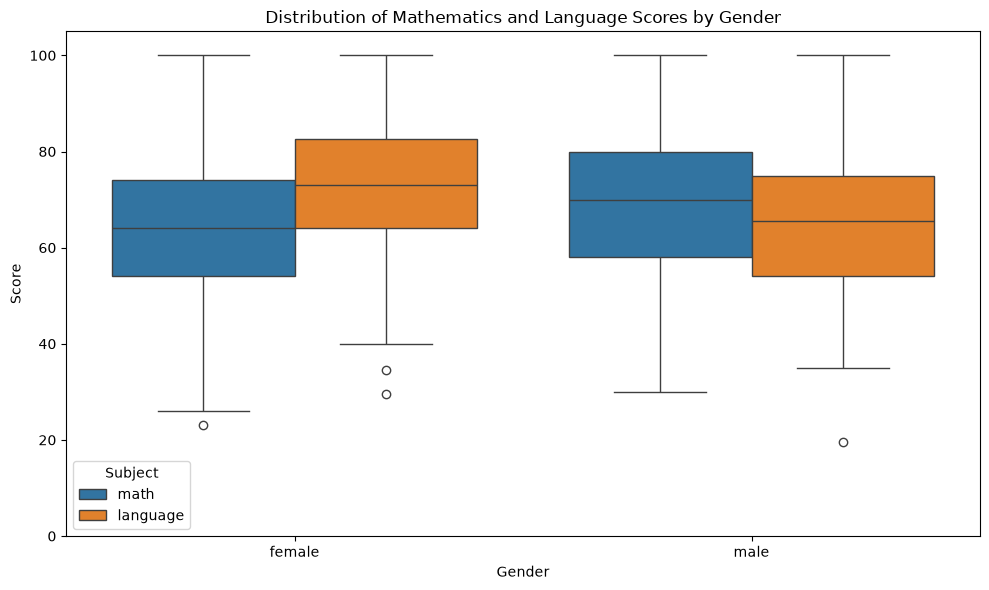

In [24]:


plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="gender",
    y="score",
    hue="subject"
)

plt.title("Distribution of Mathematics and Language Scores by Gender")
plt.xlabel("Gender")
plt.ylabel("Score")
plt.ylim(0, 105)
plt.legend(title="Subject")
plt.tight_layout()
plt.show()

# Observation
The dataset contains 486 students, each with a recorded score in Mathematics and Language. The mean Language score was 69.00 (SD = 14.45), while the mean Mathematics score was 66.38 (SD = 15.05). Thus, the average Language score was approximately 2.62 marks higher than the average Mathematics score. The standard deviations indicate that scores varied considerably in both subjects, with slightly greater variability in Mathematics.
When the results were examined by gender, female students had a higher mean Language score (M = 73.00, SD = 14.01) than male students (M = 64.93, SD = 13.75). In Mathematics, male students had a higher mean score (M = 68.95, SD = 14.43) than female students (M = 63.86, SD = 15.26). These findings describe the observed score differences; inferential statistical tests are required to assess their statistical significance.

In [25]:
# comparing scores across parental education levels
df.groupby("parental.level.of.education")["score"].agg(
    ["count", "mean", "median", "std", "min", "max"]
).round(2)

,count,mean,median,std,min,max
parental.level.of.education,,,,,,
associate's degree,354,68.92,69.5,14.76,26.0,100.0
bachelor's degree,188,70.25,70.0,14.74,29.0,100.0
high school,312,62.89,64.0,13.71,19.5,99.5
master's degree,118,72.64,73.0,14.61,40.0,100.0


In [26]:
df.groupby(
    ["parental.level.of.education", "subject"]
)["score"].mean().round(2)

parental.level.of.education  subject 
associate's degree           language    70.02
                             math        67.81
bachelor's degree            language    72.06
                             math        68.44
high school                  language    63.53
                             math        62.24
master's degree              language    75.53
                             math        69.75
Name: score, dtype: float64

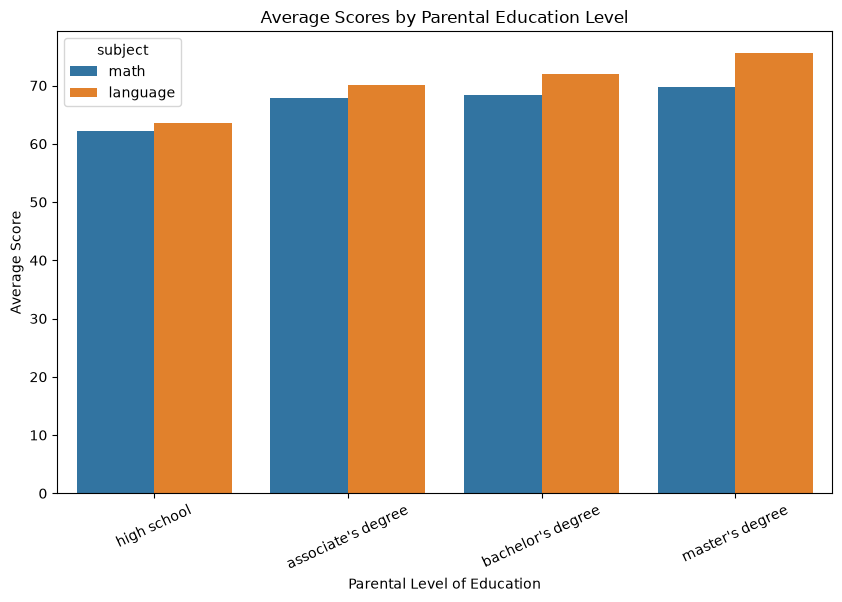

In [27]:


plt.figure(figsize=(10, 6))

sns.barplot(
    data=df,
    x="parental.level.of.education",
    y="score",
    hue="subject",
    errorbar=None
)

plt.title("Average Scores by Parental Education Level")
plt.xlabel("Parental Level of Education")
plt.ylabel("Average Score")
plt.xticks(rotation=25)
plt.show()

In [28]:
df.to_csv("scores_cleaned.csv",index=False)

### Observation 
Students whose parents held a master's degree achieved the highest mean scores in Language (75.53) and Mathematics (69.75), while students whose parents had a high school education achieved the lowest scores in both subjects (63.53 and 62.24, respectively). Language scores were higher than Mathematics scores across all parental education groups. These descriptive differences require statistical testing to determine whether they are significant.